In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

#Loading the data
df=pd.read_csv(r"C:\Users\bisha\Downloads\TimeSeries_TotalSolarGen_and_Load_IT_2016.csv")
df.head()

,utc_timestamp,IT_load_new,IT_solar_generation
0,2016-01-01T00:00:00Z,21665.0,1
1,2016-01-01T01:00:00Z,20260.0,0
2,2016-01-01T02:00:00Z,19056.0,0
3,2016-01-01T03:00:00Z,18407.0,0
4,2016-01-01T04:00:00Z,18425.0,0


## Visualising the data

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   utc_timestamp        8784 non-null   object 
 1   IT_load_new          8712 non-null   float64
 2   IT_solar_generation  8784 non-null   int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 206.0+ KB


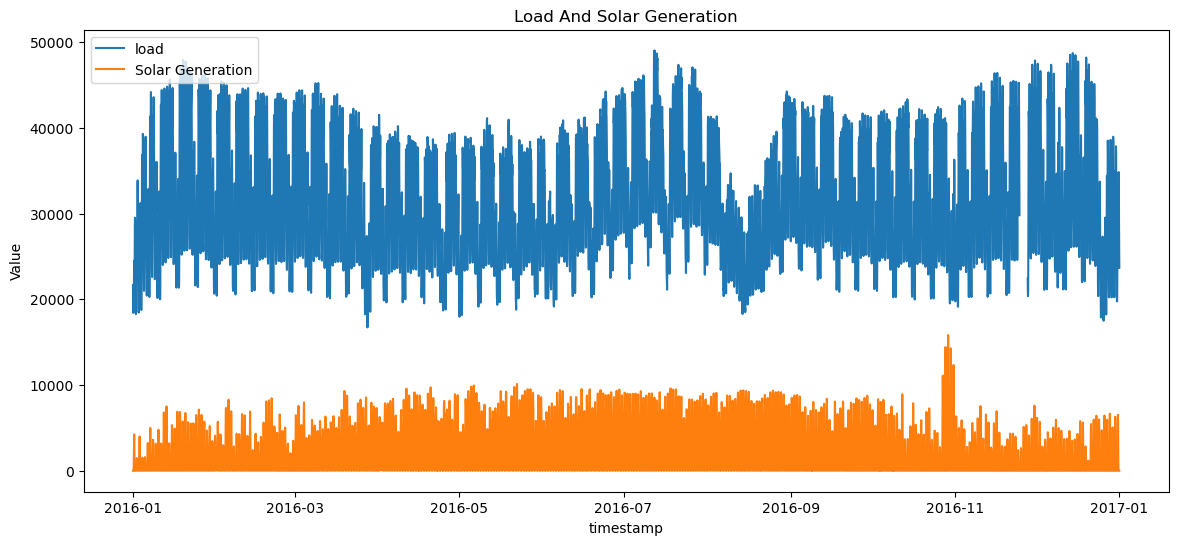

In [3]:
#Converting object dtype to datetime
df['utc_timestamp']=pd.to_datetime(df['utc_timestamp'])
plt.figure(figsize=(14,6))
plt.plot(df['utc_timestamp'],df['IT_load_new'],label='load')
plt.plot(df['utc_timestamp'],df['IT_solar_generation'],label='Solar Generation')
plt.xlabel('timestamp')
plt.ylabel('Value')
plt.legend()
plt.title('Load And Solar Generation')
plt.show()

In [4]:
df.isnull().sum()

utc_timestamp           0
IT_load_new            72
IT_solar_generation     0
dtype: int64

In [5]:
df.set_index('utc_timestamp', inplace=True)

In [6]:
df['IT_load_new'].fillna(method='ffill',inplace=True)
df.isnull().sum()

C:\Users\bisha\AppData\Local\Temp\ipykernel_26012\1850845822.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['IT_load_new'].fillna(method='ffill',inplace=True)
C:\Users\bisha\AppData\Local\Temp\ipykernel_26012\1850845822.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['IT_load_new'].fillna(method='ffill',inplace=True)


IT_load_new            0
IT_solar_generation    0
dtype: int64

## Checking For Stationarity

In [7]:
from statsmodels.tsa.stattools import adfuller
def adf_test(timeseries):
    dftest=adfuller(timeseries,autolag='AIC')
    dfoutput=pd.Series(dftest[0:4],index=['Test Statistics','P-Value','#Lags Used','Number of observation used'])
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key]=value
    print(dfoutput)

In [8]:
#Performing adf test for 'IT_LOAD_NEW'
adf_test(df['IT_load_new'])
#Performing ADF test for 'IT_solar_generation'
adf_test(df['IT_solar_generation'])

Test Statistics              -1.197390e+01
P-Value                       3.841445e-22
#Lags Used                    3.700000e+01
Number of observation used    8.746000e+03
Critical Value (1%)          -3.431098e+00
Critical Value (5%)          -2.861871e+00
Critical Value (10%)         -2.566946e+00
dtype: float64
Test Statistics              -5.741335e+00
P-Value                       6.265438e-07
#Lags Used                    3.600000e+01
Number of observation used    8.747000e+03
Critical Value (1%)          -3.431098e+00
Critical Value (5%)          -2.861870e+00
Critical Value (10%)         -2.566946e+00
dtype: float64


The P Value for it_load_new and IT_solar generation is very low so we reject the NULL hypothesise that the time series is not stationary

## Build Arima Model For "IT_LOAD_NEW"

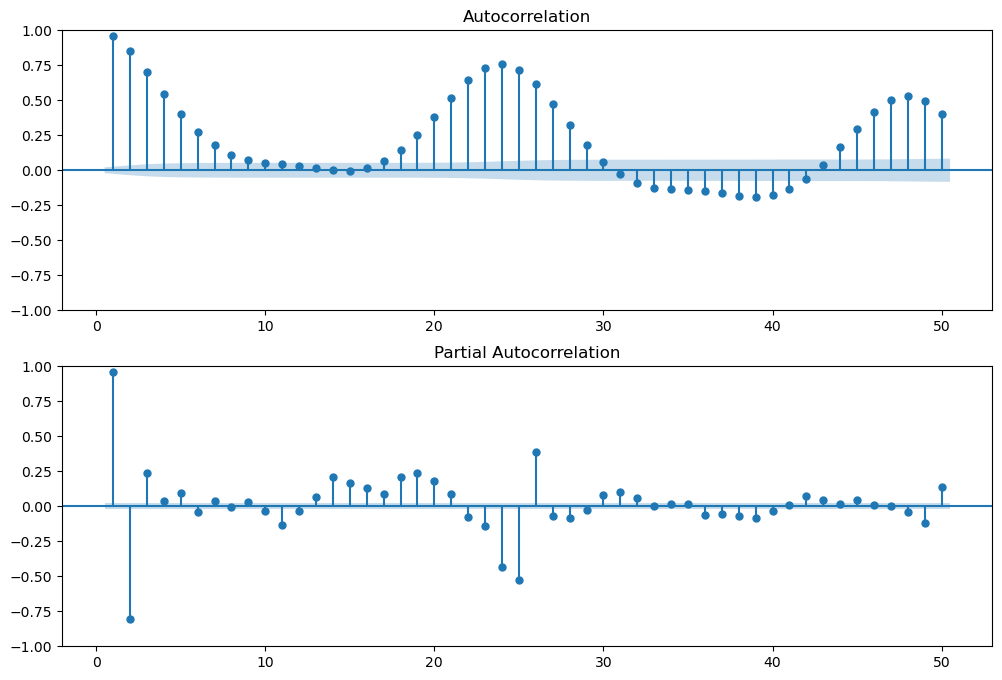

In [9]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig,(ax1,ax2)=plt.subplots(2,1,figsize=(12,8))
plot_acf(df['IT_load_new'],lags=50,zero=False,ax=ax1)
plot_pacf(df['IT_load_new'],lags=50,zero=False,ax=ax2)
plt.show()

from the graph we see the gradual decrease in acf plot and from the pacf plot we see sharp deop after lag 2. So we can take p=2,q=2 as our model parameters.

In [10]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

#split the data in test and train
train_size=int(len(df['IT_load_new'])*0.8)
train,test=df['IT_load_new'].iloc[:train_size],df['IT_load_new'].iloc[train_size:]

#Fit In THe Arima Model
model=ARIMA(train,order=(2,0,2))
model_fit=model.fit()

#Make prediction on the test set
prediction=model_fit.predict(start=len(train),end=len(train)+len(test)-1)
from math import sqrt
rmse=sqrt(mean_squared_error(test,prediction))
rmse

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


7714.9521348226

In [11]:
print(prediction)

2016-10-19 19:00:00+00:00    36655.974526
2016-10-19 20:00:00+00:00    34103.583406
2016-10-19 21:00:00+00:00    32174.231028
2016-10-19 22:00:00+00:00    30833.183085
2016-10-19 23:00:00+00:00    30008.748389
                                 ...     
2016-12-31 19:00:00+00:00    32141.902234
2016-12-31 20:00:00+00:00    32141.902234
2016-12-31 21:00:00+00:00    32141.902234
2016-12-31 22:00:00+00:00    32141.902234
2016-12-31 23:00:00+00:00    32141.902234
Freq: h, Name: predicted_mean, Length: 1757, dtype: float64


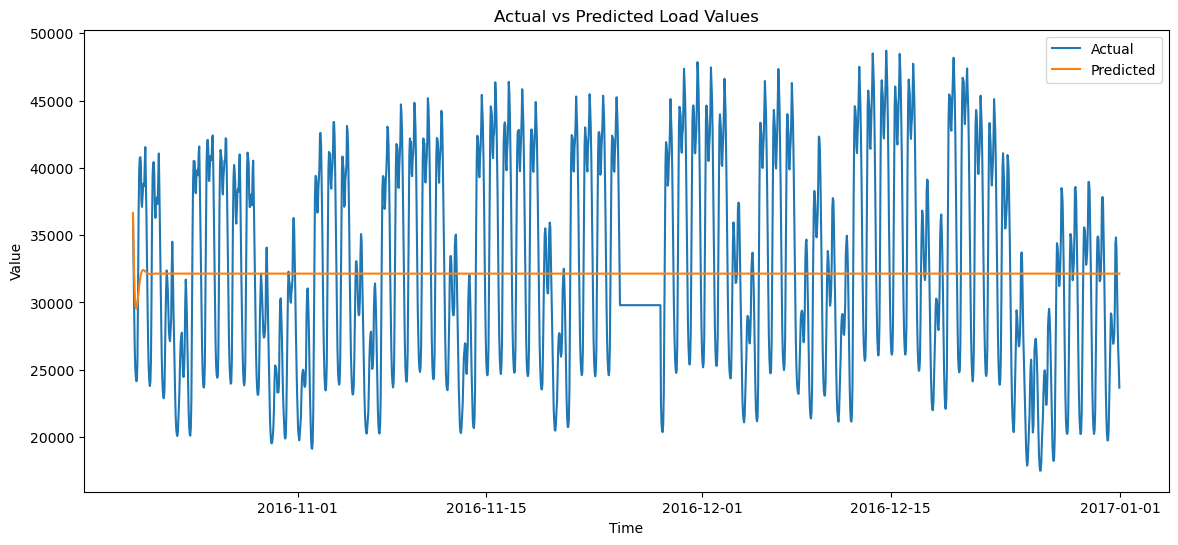

In [13]:
plt.figure(figsize=(14,6))
plt.plot(test.index,test,label='Actual')
plt.plot(test.index,prediction,label='Predicted')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.title('Actual vs Predicted Load Values')
plt.show()

- Plot shows the actual versus predicted load values for the test set. While the ARIMA model seems to capture the general pattern and structure of the time series dara,There are still some differences between the actual and predicted values.
- This is just because of data difference or very less amount of detail


## Building Model For "IT_solar_generation"